# Phase II, Pair 1, question D: front days inside the model

*What differs inside the model between a normal day and a front day, and can the state predict that the forecast will fail?*

| | |
|---|---|
| Authors | Sandro Müller K52010874 |
| Status | done |
| Phase I result this builds on | Sandro's front runs (30 front starts against 306 normal starts: about 5.3 °C too warm 3 h after the front, band holds 32 % against 81 % in normal weather) and Exp 11 (band honest on normal days, half the hours below the band with a front coming) |

## 1 · Question

What differs inside the model between a normal day and a front day, and can the state predict that the forecast will fail?

Two words need a fixed meaning for the whole notebook:

- **Front day** (the "special" case): a forecast start 12 h or 6 h before the peak of a cold front in `fronts.csv`
  (`cold_front == True`), i.e. the `front-12` and `front-6` starts of Phase I. Normal starts whose forecast window or last
  day of context contains a `cold_front` passage at that point in `events.parquet` are neither normal nor front: they are
  kept out of the normal reference.
- **Fails**: the mean absolute error of the median over the 24 forecast hours is above **2 K**. (Phase I counted hours with
  an error above 2 K; the band-miss definition is not used for "fails", band coverage is reported on its own.)

## 2 · Why this question

Phase I showed *that* the forecast breaks at fronts: the error rises to 5–7 °C and the 10–90 % band holds only 32 % of
the hours, against 81 % in normal weather. With a front coming, about half the hours fall below the whole band (Exp 11), so the band does not warn of the failure. We do not know whether anything *inside* the model is different on those days. If the state before a
front already sits apart from the states of normal days, the model "has" the information but does not turn it into a
wider band. If it does not, the failure is invisible to the model.

## 3 · Hypothesis and what would count as an answer

**Hypotheses.** For front days and normal days we ask three things:

- **H1.** Whether front states sit apart from normal states, also from temperature-matched normal cases.
- **H2.** Whether the distance from the normal states goes with failure: the error, the fail rate and the band coverage.
- **H3.** Whether this holds inside each group and within months and points, and not only because front days and normal days differ.

**What would count as an answer.**

- *A separation:* front cases are farther from their nearest normal states than normal cases are, also against temperature-matched normal cases.
- *A relation to failure:* a rank correlation between distance and error whose interval excludes zero, a fail rate and a band coverage that change across the distance bins, and an AUC for failure that differs from 0.5, also inside each group.
- *No relation:* front and normal states mixed, a correlation near 0 and an AUC near 0.5 inside the groups.

Each hypothesis is tested and answered in its own part of section 8: [H1](#h1) · [H2](#h2) · [H3](#h3).

## 4 · Setup

The code cell below holds the imports, paths and model loading. First, what the model source says that we need here.

### What the source says

*Read in `tirex2.py`, version `tirex-2==0.3.1` (as pinned) and `src/tirex2/model/tirex2.py` on `main`.*

| Point | What we found |
|---|---|
| `input_patch_size` | Set by the checkpoint config and printed below. Phase I Exp 10 found the important hours repeating every 32 h, which points to patches of 32 h. |
| Number of blocks | `len(core.stack)`, printed below. One `MultivariateBlock` (time mixer, then variate attention) per entry of the config's `stack_config.recipe`. |
| `_forward_layerwise` | `_forward_layerwise(self, x, group_vector, target_mask, known_covariate_mask)` in 0.3.1; `main` adds `indices=None`. A generator that yields the tokens after each block, `[rows, tokens, dim]`. We do not call it: forward hooks on `core.stack[b]` see the same tensors. |
| Gradients | The forward pass has no `no_grad`, but `TiRex2.predict` (and so `model.forecast`) is decorated with `@torch.no_grad`. `_predict(..., preserve_grad=True)` keeps the graph. D and E do not need gradients. |

### The state

**State = output of the last block at the last context patch**, for the row of the point.

- The last context patch is the token that holds the newest observed hours.
- The input is NaN-padded on the right by `future_len`, so the last tokens are the forecast window. The last *context* token is `L - future_len // input_patch_size - 1`.
- With sign-flip TTA, `predict` runs twice. The state is taken from the first (unflipped) pass.

The function lives in `model_state.py` next to the notebooks. **E imports the same function**, so both questions use exactly the same state.

In [1]:
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from model_state import context_token, hidden_states, state_and_forecast
from tirex2 import load_model

# ---- Paths and settings ----------------------------------------------------
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA = Path(os.environ.get("AIVIS_DATA", ROOT / "data" / "austria_15km"))
CKPT = os.environ.get("TIREX_CKPT", "NX-AI/TiRex-2")  # a local folder works too
DEVICE = os.environ.get("TIREX_DEVICE", "cpu")
RESULTS = ROOT / "data" / "notebooks" / "results" / "04_question_d"
RESULTS.mkdir(parents=True, exist_ok=True)

CONTEXT, HORIZON, SEED = 672, 24, 0  # Phase I design: 28 days of history, 24 h forecast

# ---- Load the model and print the numbers we need to know ------------------
model = load_model(CKPT, device=DEVICE)  # as in phase1-model-behavior/pair-1/run_forecasts.py
core = model.model  # the TiRex2 backbone
h = hidden_states(model, np.zeros((1, CONTEXT), np.float32))  # one dummy context, to read the token layout
print(f"input_patch_size {core.input_patch_size} | blocks {len(core.stack)} | embedding_dim {core.embedding_dim}")
print(
    f"tokens per input {h.shape[2]} | state token {context_token(core, h.shape[2])} | context_len {core.context_len}"
    f" | future_len {core.future_len} | tta_sign_flip {core.tta_sign_flip}"
)

input_patch_size 32 | blocks 12 | embedding_dim 512
tokens per input 74 | state token 63 | context_len 2048 | future_len 320 | tta_sign_flip False


## 5 · Data

Phase I design: 672 h context, 24 h horizon, start times and points of `tirex2_forecasts.npz` (336 starts × 378 points:
306 normal grid starts and 30 front starts). The context is filled exactly as in `run_forecasts.py`.

`FULL = True` uses all 336 × 378 cases (about 75 min on CPU, as in Phase I). The default is a sample:
**all front starts**, plus for each front start `N_MATCH` normal starts at the nearest hour of day and the nearest date
(at least 3 days away from any cold-front peak), at `N_POINTS` points spread over Austria (farthest-point sampling).
Matching by season and hour of day keeps the daily cycle and the season from separating the groups on their own.

The states (and the forecasts computed with them) are saved to `data/notebooks/results/04_question_d/`, not to git.

In [2]:
# ---- Settings (change them here) -------------------------------------------
FULL = False  # True: all 336 x 378 cases (about 75 min); False: a sample
N_MATCH = 2  # normal starts matched to each front start
N_POINTS = 120  # points per start, spread over Austria
FAIL_K = 2.0  # "fails": MAE of the median over 24 h above this (K)

# ---- Load the data ---------------------------------------------------------
pts = pd.read_csv(DATA / "points_with_labels.csv").set_index("point_id")  # coordinates of the points
grid = pd.read_parquet(DATA / "grid_long.parquet", columns=["point_id", "time", "T2M"])
OBS = grid.pivot(index="time", columns="point_id", values="T2M")  # observed temperature, with gaps (for scoring)
T = OBS.interpolate(limit_area="inside").ffill().bfill()  # gaps filled (for the model input), as in run_forecasts.py
times, pids = T.index, T.columns.to_numpy()
SER = T.to_numpy(np.float32)  # filled temperature: SER[hour, point]
OBSV = OBS.to_numpy(np.float32)  # observed temperature: OBSV[hour, point]

# hour index of every cold-front peak
fronts = pd.read_csv(DATA / "fronts.csv", parse_dates=["peak_time"])
front_peaks = times.get_indexer(pd.to_datetime(fronts[fronts.cold_front].peak_time, utc=True))

# ---- The Phase I forecasts: start times, tags and the forecasts themselves -
P1 = np.load(DATA / "tirex2_forecasts.npz", allow_pickle=True)
tags = P1["tags"].astype(str)  # "grid", "front-12", "front-6", ...
origin = P1["origin_idx"].astype(int)  # hour index of each forecast start
p1_col = {p: k for k, p in enumerate(P1["pids"])}  # point id -> column in the Phase I arrays
assert (P1["times"] == times.astype("int64").to_numpy()).all(), "time axis differs from the Phase I file"


# ---- Choose the start times ------------------------------------------------
def hour_gap(a, b):
    """Difference between the hours of day of two Phase I starts, around the clock (0 to 12 h)."""
    d = abs(times[origin[a]].hour - times[origin[b]].hour)
    return min(d, 24 - d)


def closeness(g, k):
    """Sort key for a normal start g next to a front start k: first the same hour of day, then the nearest date."""
    return (hour_gap(g, k), abs(origin[g] - origin[k]))


front_k = np.where(np.char.startswith(tags, "front"))[0]  # Phase I rows of the front starts
grid_k = np.where(tags == "grid")[0]  # Phase I rows of the normal starts
if FULL:
    start_k = np.r_[grid_k, front_k]
else:
    # normal starts at least 72 h away from any cold-front peak ...
    far = grid_k[[np.abs(front_peaks - origin[k]).min() >= 72 for k in grid_k]]
    # ... and for each front start the N_MATCH ones closest in hour of day and date
    match = set()
    for k in front_k:
        candidates = sorted(far, key=lambda g: closeness(g, k))
        match.update(int(g) for g in candidates[:N_MATCH])
    start_k = np.r_[np.sort(list(match)).astype(int), front_k]

# ---- Choose the points -----------------------------------------------------
XY = pts.loc[pids, ["x", "y"]].to_numpy(float) / 1000  # position of every point in km
if FULL or N_POINTS >= len(pids):
    chosen = np.arange(len(pids))
else:
    # farthest-point sampling: start with one random point, then keep adding the point
    # that is farthest from all points chosen so far
    rng = np.random.default_rng(SEED)
    chosen = [int(rng.integers(len(pids)))]
    while len(chosen) < N_POINTS:
        dist_to_chosen = np.linalg.norm(XY[:, None] - XY[chosen][None], axis=-1).min(axis=1)
        chosen.append(int(np.argmax(dist_to_chosen)))
    chosen = np.array(chosen)

# ---- One row per case = one start time at one point ------------------------
cases = pd.DataFrame(
    [(int(k), origin[k], tags[k], int(j), pids[j]) for k in start_k for j in chosen],
    columns=["p1_k", "i", "tag", "j", "pid"],
)
print(f"{len(start_k)} starts ({np.isin(start_k, front_k).sum()} front) x {len(chosen)} points = {len(cases)} cases")

72 starts (30 front) x 120 points = 8640 cases


In [3]:
# The state of every case is computed once and saved (states.npz); a second run only loads it.
path = RESULTS / "states.npz"
key = cases[["i", "pid"]].to_numpy()  # identifies the cases the saved file was made for
if path.exists() and np.array_equal(np.load(path)["key"], key):
    z = np.load(path)
    STATES, FRESH = z["states"], z["preds"]
else:
    t0 = time.time()
    ctx = np.stack([SER[i - CONTEXT : i, j] for i, j in zip(cases.i, cases.j)])  # the 672 h before each start
    STATES, FRESH = state_and_forecast(model, ctx, HORIZON, batch_size=128)  # state + a fresh forecast per case
    np.savez_compressed(path, key=key, states=STATES, preds=FRESH)
    print(f"states for {len(cases)} cases in {time.time() - t0:.0f}s")
print("states", STATES.shape)

states (8640, 512)


### Labels

- **Group**: `front` (front-12 / front-6 starts), `normal` (grid starts with no `cold_front` passage at that point from 24 h
  before to 24 h after the start in `events.parquet`), `excluded` (grid starts with such a passage).
- **Error, fail and coverage** from the Phase I forecasts in `tirex2_forecasts.npz`, so the model is not run again for
  them: MAE of the median over 24 h against the observed temperature, `fail = MAE > 2 K`, and the share of the 24 hours
  inside the 10–90 % band.
- **Control variables** for the checks: temperature of the last 24 h of context, month, hour of day.

The forecasts computed together with the states must reproduce the Phase I file (checked here for every case).

In [4]:
# ---- Cold-front passages at each point, from the event table ---------------
ev = pd.read_parquet(DATA / "events.parquet", columns=["point_id", "time", "kind"])
ev = ev[ev.kind == "cold_front"]
ev_t = times.get_indexer(pd.to_datetime(ev.time, utc=True))
passage = {}  # point id -> hour indices of its cold-front passages
for p, t in zip(ev.point_id, ev_t):
    passage.setdefault(p, []).append(t)


def has_passage(pid, i):
    """True if the point has a cold-front passage from 24 h before the start to the end of the forecast window."""
    return any(i - 24 <= t < i + HORIZON for t in passage.get(pid, []))


# ---- Group: front / normal / excluded --------------------------------------
is_front = cases.tag.str.startswith("front").to_numpy()
has_event = np.array([has_passage(p, i) for p, i in zip(cases.pid, cases.i)])
cases["group"] = np.where(is_front, "front", np.where(has_event, "excluded", "normal"))

# ---- Error, fail and band coverage from the Phase I forecasts --------------
preds_p1 = P1["preds"]  # read the array from the file once, not once per case
PRED = np.stack([preds_p1[k, p1_col[p]] for k, p in zip(cases.p1_k, cases.pid)]).astype(np.float32)
obs = np.stack([OBSV[i : i + HORIZON, j] for i, j in zip(cases.i, cases.j)])  # observed temperature, 24 h
cases["mae"] = np.nanmean(np.abs(PRED[:, 4] - obs), axis=1)  # PRED[:, 4] is the median
cases["fail"] = cases.mae > FAIL_K
inside = ((obs >= PRED[:, 0]) & (obs <= PRED[:, 8])).astype(float)  # inside the 10-90 % band
cases["coverage"] = np.nanmean(np.where(np.isnan(obs), np.nan, inside), axis=1)

# ---- Control variables for the checks --------------------------------------
cases["t_last"] = [SER[i - 24 : i, j].mean() for i, j in zip(cases.i, cases.j)]  # temperature of the last 24 h
cases["month"] = times[cases.i].month
cases["hour"] = times[cases.i].hour

# ---- The fresh forecasts must reproduce the Phase I file -------------------
diff = np.abs(FRESH - PRED)
print(f"fresh forecast vs tirex2_forecasts.npz: max |diff| {diff.max():.4f} °C, mean {diff.mean():.5f} °C")
cases.groupby("group").agg(
    n=("mae", "size"),
    mae=("mae", "mean"),
    fail_rate=("fail", "mean"),
    coverage=("coverage", "mean"),
    t_last=("t_last", "mean"),
).round(3)

fresh forecast vs tirex2_forecasts.npz: max |diff| 0.0156 °C, mean 0.00269 °C


,n,mae,fail_rate,coverage,t_last
group,,,,,
front,3600,3.005,0.737,0.602,14.305
normal,5040,1.773,0.350,0.788,15.756


## 6 · Technique 1: 2D projection

> **Technique used:** projection plot of internal representations (PCA, then UMAP; lecture list: projection plots). Dimensionality reduction can distort the picture, so the section 8 overview compares it with the full state space. In the code: the cell with `PCA` and `umap.UMAP`.

States standardised per dimension, then PCA (50 components), then UMAP (`random_state` fixed). Coloured by group and by
error.

*What it shows:* whether front and normal states form separate regions, and whether high errors gather somewhere.
*What it cannot show:* distances. UMAP keeps neighbourhoods, not distances, and can draw clusters that are not there, so it
is an illustration only; the evidence is the distance in the full state space (Technique 2).

PCA: first 2 components 61%, 50 components 99%


/usr/local/lib/python3.12/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/usr/local/lib/python3.12/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


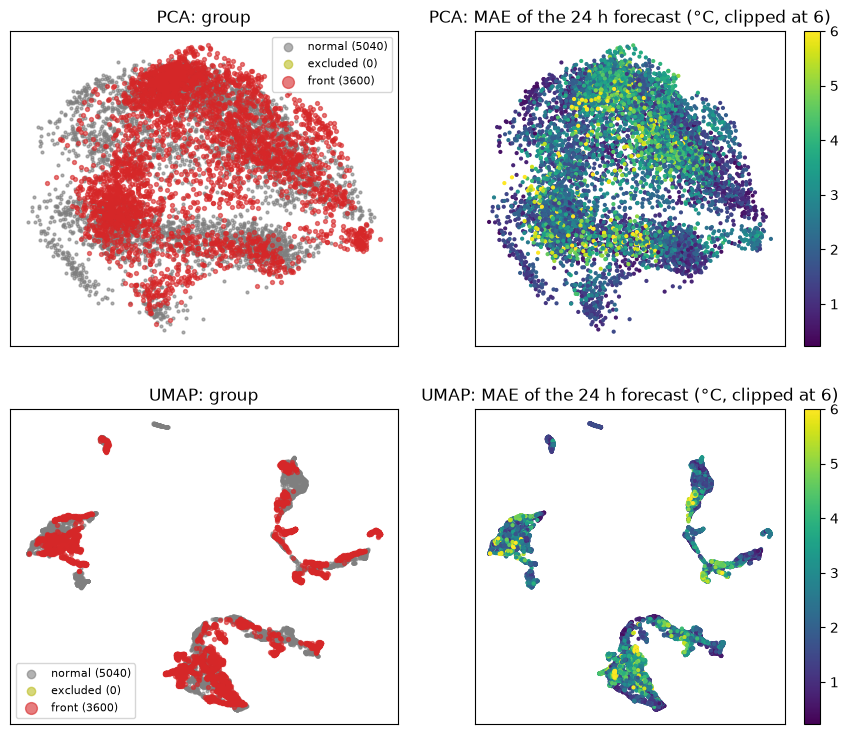

In [5]:
import umap
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# TECHNIQUE: projection plot of internal representations (PCA, then UMAP)
# ---- Standardise every state dimension, then PCA to 50 components, then UMAP to 2D ----
Z = StandardScaler().fit_transform(STATES)
pca = PCA(n_components=min(50, Z.shape[1], len(Z) - 1), random_state=SEED).fit(Z)
ZP = pca.transform(Z)
print(
    f"PCA: first 2 components {pca.explained_variance_ratio_[:2].sum():.0%}, 50 components {pca.explained_variance_ratio_.sum():.0%}"
)
EMB = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=SEED).fit_transform(ZP)
cases["u1"], cases["u2"] = EMB[:, 0], EMB[:, 1]
cases["pc1"], cases["pc2"] = ZP[:, 0], ZP[:, 1]

# ---- Four panels: PCA and UMAP, each coloured by group and by error ----------
colors = {"normal": "tab:gray", "excluded": "tab:olive", "front": "tab:red"}
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for row, (a, b, name) in enumerate([("pc1", "pc2", "PCA"), ("u1", "u2", "UMAP")]):
    ax = axes[row, 0]  # left: coloured by group
    for g in ["normal", "excluded", "front"]:
        d = cases[cases.group == g]
        ax.scatter(d[a], d[b], s=4 if g != "front" else 8, c=colors[g], label=f"{g} ({len(d)})", alpha=0.6)
    ax.set(title=f"{name}: group", xticks=[], yticks=[])
    ax.legend(markerscale=3, fontsize=8)
    # right: coloured by the error (clipped at 6 so that a few large errors do not wash out the scale)
    sc = axes[row, 1].scatter(cases[a], cases[b], s=4, c=cases.mae.clip(upper=6), cmap="viridis")
    axes[row, 1].set(title=f"{name}: MAE of the 24 h forecast (°C, clipped at 6)", xticks=[], yticks=[])
    fig.colorbar(sc, ax=axes[row, 1])
fig.savefig(RESULTS / "projection_static.png", dpi=150, bbox_inches="tight")

## 7 · Technique 2: distance to the nearest normal states

> **Technique used:** pairwise distances between activations (the mean distance of each state to its 10 nearest normal states, in the full state space; lecture list: pairwise distances between activations). Only the state of the last block is used. In the code: `knn_distance()`.

For every case: mean Euclidean distance (standardised full state) to its `K` nearest **normal** states. Neighbours at the
**same point less than 28 days apart are left out**, the case itself included: their 672 h contexts overlap, so they
would be close for a trivial reason.

Then: is the distance larger for front cases? Is it also larger than for *normal cold* cases (each front case paired with
the normal case at the same point whose last-24 h temperature is closest), so that it is not just the cold? How does the
distance relate to the error (Spearman, bootstrap over start times), the fail rate and the band coverage per distance bin?

*What it shows:* whether the model's internal state "knows" the case is unusual, measured where it matters. *What it
cannot show:* why; and a distance is only relative to the normal cases we have.

In [6]:
from IPython.display import display
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

K, SAME_POINT_DAYS = 10, 28  # 10 nearest neighbours; same-point neighbours closer than 28 days are left out


def knn_distance(query, ref, q_meta, r_meta, k=K, chunk=512):
    """Mean distance to the k nearest reference rows, leaving out the same point within SAME_POINT_DAYS.
    q_meta and r_meta hold (point id, start hour) for the query and the reference rows."""
    out = np.empty(len(query))
    rn = (ref**2).sum(1)
    for s in range(0, len(query), chunk):  # in chunks, so the distance matrix stays small
        q = query[s : s + chunk]
        d2 = (q**2).sum(1)[:, None] + rn[None] - 2 * q @ ref.T  # squared distances to all reference rows
        # same point and starts less than SAME_POINT_DAYS apart: their contexts overlap, so skip them
        same = (q_meta[s : s + chunk, None, 0] == r_meta[None, :, 0]) & (
            np.abs(q_meta[s : s + chunk, None, 1] - r_meta[None, :, 1]) < SAME_POINT_DAYS * 24
        )
        d2[same] = np.inf
        out[s : s + chunk] = np.sqrt(np.maximum(np.partition(d2, k, axis=1)[:, :k], 0)).mean(1)
    return out


# TECHNIQUE: pairwise distances between activations (kNN distance of each state to the normal states)
# ---- Distance of every case to its nearest normal states -------------------
meta = cases[["pid", "i"]].to_numpy()
normal = (cases.group == "normal").to_numpy()
cases["dist"] = knn_distance(Z, Z[normal], meta, meta[normal])

# ---- Temperature-matched normal cases: per front case, the normal case at the same point
# whose temperature of the last 24 h is closest -------------------------------
cold_pair = []
for _, c in cases[cases.group == "front"].iterrows():
    d = cases[normal & (cases.pid == c.pid).to_numpy()]
    if d.empty:
        continue
    cold_pair.append(int((d.t_last - c.t_last).abs().idxmin()))
cases["cold_match"] = False
cases.loc[cold_pair, "cold_match"] = True


def rho(d):
    """Spearman rank correlation between the distance and the error."""
    return spearmanr(d.dist, d.mae).statistic


def boot(f, df, n=1000, seed=SEED):
    """95 % interval of f, resampling whole start times (cases of one start are not independent)."""
    r = np.random.default_rng(seed)
    starts = df.i.unique()
    vals = [f(df[df.i.isin(r.choice(starts, len(starts)))]) for _ in range(n)]
    return np.nanpercentile(vals, [2.5, 97.5])


# ---- Table: distance, correlation with the error and AUC for "fail" ---------
rows = []
for name, d in [
    ("all", cases[cases.group != "excluded"]),
    ("normal", cases[normal]),
    ("front", cases[cases.group == "front"]),
]:
    lo, hi = boot(rho, d)
    auc = roc_auc_score(d.fail, d.dist) if d.fail.nunique() == 2 else np.nan
    rows.append(
        {
            "cases": name,
            "n": len(d),
            "dist_median": d.dist.median(),
            "spearman_dist_mae": rho(d),
            "ci_lo": lo,
            "ci_hi": hi,
            "auc_dist_for_fail": auc,
        }
    )
rows.append(
    {
        "cases": "normal, temperature-matched to fronts",
        "n": len(cold_pair),
        "dist_median": cases.loc[cold_pair, "dist"].median(),
    }
)
dist_table = pd.DataFrame(rows)
dist_table.to_csv(RESULTS / "distance_table.csv", index=False)

# ---- Table: fail rate and band coverage per distance bin (quintiles of all cases) ----
used = cases[cases.group != "excluded"].copy()
used["bin"] = pd.qcut(used.dist, 5, labels=[f"Q{q}" for q in range(1, 6)])
by_bin = used.groupby(["bin", "group"], observed=True).agg(
    n=("mae", "size"),
    dist=("dist", "median"),
    mae=("mae", "mean"),
    fail_rate=("fail", "mean"),
    coverage=("coverage", "mean"),
)
display(dist_table.round(3))
by_bin.round(3)

,cases,n,dist_median,spearman_dist_mae,ci_lo,ci_hi,auc_dist_for_fail
0,all,8640,6.379,0.290,0.211,0.361,0.643
1,normal,5040,5.390,-0.020,-0.091,0.061,0.510
2,front,3600,7.945,-0.083,-0.171,0.018,0.476
3,"normal, temperature-matched to fronts",3600,5.322,NaN,NaN,NaN,NaN


n   dist    mae  fail_rate  coverage
bin group                                          
Q1  front     11  4.730  3.547      1.000     0.489
    normal  1717  4.312  1.777      0.340     0.814
Q2  front    215  5.649  3.175      0.800     0.618
    normal  1513  5.362  1.784      0.359     0.782
Q3  front    655  6.471  3.067      0.763     0.606
    normal  1073  6.327  1.756      0.349     0.763
Q4  front   1233  7.610  3.019      0.722     0.598
    normal   495  7.419  1.807      0.372     0.769
Q5  front   1486  9.572  2.938      0.727     0.603
    normal   242  9.338  1.685      0.322     0.796

### Figures

In [7]:
import plotly.graph_objects as go

# ---- Interactive UMAP with a colour toggle (group / error / fail) ----------
hover = [
    f"point {p}<br>{times[i]:%Y-%m-%d %H} UTC<br>{g}<br>MAE {m:.1f} °C"
    for p, i, g, m in zip(cases.pid, cases.i, cases.group, cases.mae)
]
group_colors = cases.group.map({"normal": "#9e9e9e", "excluded": "#b5b35c", "front": "#d62728"})
modes = {  # the three colourings the buttons switch between
    "group": {"color": group_colors, "showscale": False},
    "error (MAE, °C)": {"color": cases.mae.clip(upper=6), "colorscale": "Viridis", "showscale": True},
    "fail (MAE > 2 K)": {"color": np.where(cases.fail, "#d62728", "#9e9e9e"), "showscale": False},
}
fig = go.Figure(
    go.Scattergl(
        x=cases.u1, y=cases.u2, mode="markers", text=hover, hoverinfo="text", marker={"size": 4, **modes["group"]}
    )
)
fig.update_layout(
    title="UMAP of the model state (last block, last context patch) — illustration only",
    xaxis={"visible": False},
    yaxis={"visible": False},
    width=850,
    height=650,
    updatemenus=[
        {
            "buttons": [
                {"label": k, "method": "restyle", "args": [{f"marker.{a}": [v] for a, v in m.items()}]}
                for k, m in modes.items()
            ],
            "x": 0,
            "y": 1.08,
            "xanchor": "left",
        }
    ],
)
fig.write_html(RESULTS / "projection.html")
fig

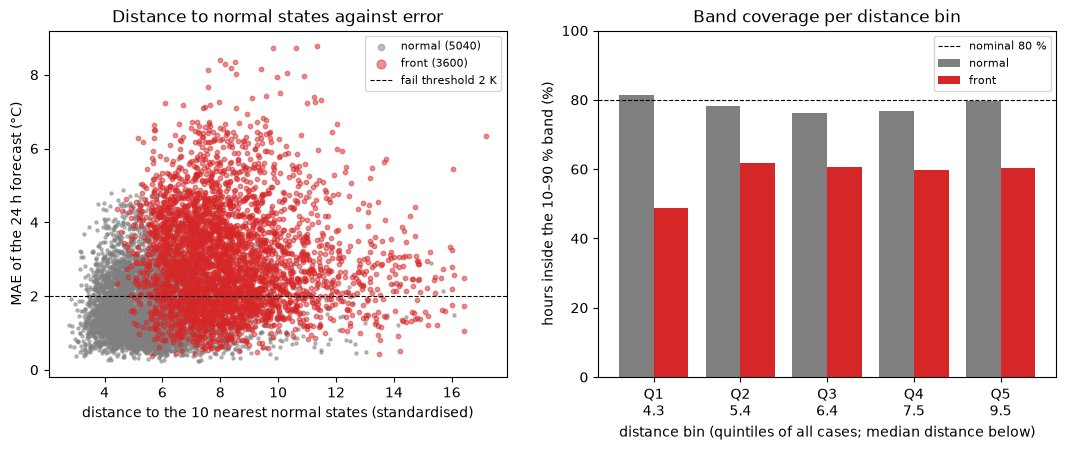

In [8]:
# ---- Left: distance against error for every case. Right: band coverage per distance bin ----
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
for g, c in [("normal", "tab:gray"), ("front", "tab:red")]:
    d = cases[cases.group == g]
    ax.scatter(d.dist, d.mae, s=5 if g == "normal" else 10, c=c, alpha=0.5, label=f"{g} ({len(d)})")
ax.axhline(2, color="k", lw=0.8, ls="--", label=f"fail threshold {FAIL_K:g} K")
ax.set(
    xlabel="distance to the 10 nearest normal states (standardised)",
    ylabel="MAE of the 24 h forecast (°C)",
    title="Distance to normal states against error",
)
ax.legend(markerscale=2, fontsize=8)

ax = axes[1]
cov = used.groupby(["bin", "group"], observed=True).coverage.mean().unstack()  # bins x groups
x = np.arange(len(cov))
for n, (g, c) in enumerate([("normal", "tab:gray"), ("front", "tab:red")]):
    if g in cov:
        ax.bar(x + (n - 0.5) * 0.4, cov[g] * 100, 0.4, color=c, label=g)
ax.axhline(80, color="k", lw=0.8, ls="--", label="nominal 80 %")
ax.set_xticks(x, [f"{b}\n{used[used.bin == b].dist.median():.1f}" for b in cov.index])
ax.set(
    xlabel="distance bin (quintiles of all cases; median distance below)",
    ylabel="hours inside the 10–90 % band (%)",
    ylim=(0, 100),
    title="Band coverage per distance bin",
)
ax.legend(fontsize=8)
fig.savefig(RESULTS / "distance_error_coverage.png", dpi=150, bbox_inches="tight")

## 8 · Results per hypothesis

The two techniques (sections 6 and 7) ran on all cases. Here the results are read **one hypothesis at a time**:
[H1](#h1) → [H2](#h2) → [H3](#h3), after an overview.

### 8.0 · Overview: do the two techniques agree?

> **Technique used:** comparing two views of the same states (the projection against the full state space; lecture list: comparing techniques). In the code: `front_share()`.

For every front case: the share of its 10 nearest neighbours that are front cases, once in the full standardised state,
once in the PCA-50 and once in the 2D UMAP. If all are near the overall share of front cases, no technique shows a front
region. If UMAP shows a much higher share than the full space, the picture exaggerates the separation.

*Caveat: neighbours from the same start (other points at the same time) are not excluded, and they are front cases by
definition, so these shares are higher than they would be for neighbours from other fronts.*

In [9]:
from sklearn.neighbors import NearestNeighbors


# TECHNIQUE: comparing two views of the same states (projection against the full state space)
def front_share(X):
    """Share of front cases among the 10 nearest neighbours of a front case, in the space X."""
    nn = NearestNeighbors(n_neighbors=11).fit(X)  # 11 because the nearest neighbour of a case is itself
    idx = nn.kneighbors(X[(cases.group == "front").to_numpy()], return_distance=False)[:, 1:]
    return (cases.group.to_numpy()[idx] == "front").mean()


base_share = (cases.group == "front").mean()  # the share we would see if front cases were scattered at random
print(f"share of front cases overall: {base_share:.2f}")
print(
    f"share of front cases among the 10 nearest neighbours of a front case: full state {front_share(Z):.2f},"
    f" PCA-50 {front_share(ZP):.2f}, UMAP 2D {front_share(EMB):.2f}"
)

share of front cases overall: 0.42


share of front cases among the 10 nearest neighbours of a front case: full state 0.90, PCA-50 0.89, UMAP 2D 0.83


<a id="h1"></a>
### 8.1 · H1: do front states sit apart from normal states?

*Evidence: the median distance to the 10 nearest normal states for normal cases, front cases and temperature-matched normal cases. Back to the hypotheses: [section 3](#3-·-Hypothesis-and-what-would-count-as-an-answer).*

In [10]:
# H1: do front states sit apart from normal states? Median distance to the 10 nearest normal states.
display(dist_table[["cases", "n", "dist_median"]].round(3))

,cases,n,dist_median
0,all,8640,6.379
1,normal,5040,5.390
2,front,3600,7.945
3,"normal, temperature-matched to fronts",3600,5.322


**Result:** Front states sit apart from normal states. The median distance to the 10 nearest normal states is 7.9 for front cases, 5.4 for normal cases and 5.3 for normal cases matched to the temperature of the fronts, so the difference is not just the cold.

**Evidence:** the table in section 7 (median distance: front 7.945, normal 5.390, temperature-matched normal 5.322) and the overview in 8.0: among the 10 nearest neighbours of a front case, 0.90 are front cases in the full state, 0.89 in PCA-50 and 0.83 in the 2D UMAP, against 0.42 overall. The 2D picture therefore does not exaggerate the separation.

**What it means:** The state before a front differs from the state on normal days, also when the temperature is the same. Open: the share of front neighbours is inflated, because cases of the same start are front cases by definition (see the caveat in 8.0 and "Further ideas", item 1).

<a id="h2"></a>
### 8.2 · H2: does the distance go with failure?

*Evidence: Spearman correlation (with its bootstrap interval) and AUC of the distance for "fail", overall and inside each group, and fail rate and band coverage per distance bin. Back to the hypotheses: [section 3](#3-·-Hypothesis-and-what-would-count-as-an-answer).*

In [11]:
# H2: does the distance go with failure? Rank correlation and AUC overall and inside each group, then per distance bin.
display(dist_table.loc[:2, ["cases", "n", "spearman_dist_mae", "ci_lo", "ci_hi", "auc_dist_for_fail"]].round(3))
by_bin.round(3)

,cases,n,spearman_dist_mae,ci_lo,ci_hi,auc_dist_for_fail
0,all,8640,0.290,0.211,0.361,0.643
1,normal,5040,-0.020,-0.091,0.061,0.510
2,front,3600,-0.083,-0.171,0.018,0.476


n   dist    mae  fail_rate  coverage
bin group                                          
Q1  front     11  4.730  3.547      1.000     0.489
    normal  1717  4.312  1.777      0.340     0.814
Q2  front    215  5.649  3.175      0.800     0.618
    normal  1513  5.362  1.784      0.359     0.782
Q3  front    655  6.471  3.067      0.763     0.606
    normal  1073  6.327  1.756      0.349     0.763
Q4  front   1233  7.610  3.019      0.722     0.598
    normal   495  7.419  1.807      0.372     0.769
Q5  front   1486  9.572  2.938      0.727     0.603
    normal   242  9.338  1.685      0.322     0.796

**Result:** Inside the groups, the distance has no relation to failure. Over all cases it goes with the error (correlation 0.29), but only because front cases are both farther away and fail more often.

**Evidence:** rank correlation of distance and error: 0.29 overall (95 % interval 0.21 to 0.36), −0.02 inside normal cases (−0.09 to 0.06) and −0.08 inside front cases (−0.17 to 0.02). AUC of the distance for "fails": 0.64 overall, 0.51 inside normal cases, 0.48 inside front cases. Per distance bin the fail rate stays between 0.32 and 0.37 for normal cases, and between 0.72 and 0.80 for front cases in bins Q2 to Q5 (Q1 has only 11 front cases). The coverage stays between 0.76 and 0.81 for normal cases and between 0.60 and 0.62 for front cases in Q2 to Q5.

**What it means:** The state tells front days from normal days, but the distance does not tell how badly a given day will fail, and the band covers about the same share of hours at every distance. The coverage at fronts here (0.60) is not the 32 % from Phase I: that number comes from Phase I's own front runs, and we did not check that the windows match, so the two are not compared.

<a id="h3"></a>
### 8.3 · H3: does it hold inside each group, months and points?

*Evidence: the checks in section 9 (AUC of the distance within months and points; the state against season, hour, position and last temperature, split by point and by month). Back to the hypotheses: [section 3](#3-·-Hypothesis-and-what-would-count-as-an-answer).*

**Result:** Inside a group the distance does not hold up as a predictor of failure (8.2). The AUC within months and points (0.65) mixes front and normal cases, so it mostly repeats the group difference. A classifier on the state predicts failure better than season, hour, position and last temperature alone when split by point (AUC 0.71 against 0.63; 0.73 together), and, weakly, when split by month (0.575 against 0.465, with only 7 months).

**Evidence:** the AUC numbers and the table in section 9: within month 0.651 (7 groups), within point 0.657 (120 groups); by point: state 0.713, controls 0.630, both 0.733; by month: state 0.575, controls 0.465, both 0.580.

**What it means:** The state carries some information about failure beyond season and place, but the distance to normal states does not capture it inside a group. Open: the classifier was not run inside each group, so it may be using the front itself (74 % of front cases fail against 35 % of normal cases).

## 9 · Checks

*Does the result hold on other dates, other points, other groups? What did we try to break it with?*

1. **Fresh forecast vs Phase I:** the forecasts computed with the states must match `tirex2_forecasts.npz`.
2. **Same cases and state for both techniques:** Technique 1 and 2 use the same `STATES` rows, in the same order.
3. **Not just season or point:**
   - AUC of the distance for "fail" *within* each month and *within* each point (only groups with both outcomes),
   - a logistic regression on the state (PCA-20) against one on season, hour, position and last-day temperature only, both
     evaluated with splits **by point** and **by month** (never random: neighbouring starts at a point share most of their
     context).
4. **Not just the cold:** the front distances against the temperature-matched normal cases (section 7 table).

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline

# ---- 1 the fresh forecasts must match the Phase I file
assert np.abs(FRESH - PRED).max() < 0.05, "fresh forecasts do not reproduce tirex2_forecasts.npz"

# ---- 2 both techniques use the same cases and states, in the same order
assert len(STATES) == len(cases) == len(EMB) and np.array_equal(np.load(RESULTS / "states.npz")["key"], key)


# ---- 3a AUC of the distance for fail, inside each month and inside each point
def auc_within(col):
    a = [roc_auc_score(d.fail, d.dist) for _, d in used.groupby(col) if d.fail.nunique() == 2]
    return (np.mean(a) if a else np.nan), len(a)


for col in ["month", "pid"]:
    m, n = auc_within(col)
    print(f"AUC of distance for fail, within {col}: mean {m:.3f} over {n} groups")

# ---- 3b the state against season, hour, position and temperature alone, split by point and by month
# (never a random split: neighbouring starts at a point share most of their context)
X_state = ZP[:, :20][(cases.group != "excluded").to_numpy()]
X_ctrl = np.c_[
    np.sin(2 * np.pi * used.month / 12),
    np.cos(2 * np.pi * used.month / 12),
    np.sin(2 * np.pi * used.hour / 24),
    np.cos(2 * np.pi * used.hour / 24),
    pts.loc[used.pid, ["x", "y"]].to_numpy() / 1e5,
    used.t_last,
]
y = used.fail.to_numpy()
res = []
for split in ["pid", "month"]:
    groups = used[split].to_numpy()
    n_splits = min(5, len(np.unique(groups)))
    for name, X in [
        ("state (PCA-20)", X_state),
        ("season, hour, position, t_last", X_ctrl),
        ("state + controls", np.c_[X_state, X_ctrl]),
    ]:
        p = np.full(len(y), np.nan)
        for tr, te in GroupKFold(n_splits=n_splits).split(X, y, groups):
            if len(np.unique(y[tr])) < 2:
                continue
            clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(X[tr], y[tr])
            p[te] = clf.predict_proba(X[te])[:, 1]
        ok = ~np.isnan(p)
        res.append(
            {
                "split by": split,
                "features": name,
                "AUC": roc_auc_score(y[ok], p[ok]) if len(np.unique(y[ok])) == 2 else np.nan,
            }
        )
pd.DataFrame(res).round(3)

AUC of distance for fail, within month: mean 0.651 over 7 groups


AUC of distance for fail, within pid: mean 0.657 over 120 groups


,split by,features,AUC
0,pid,state (PCA-20),0.713
1,pid,"season, hour, position, t_last",0.630
2,pid,state + controls,0.733
3,month,state (PCA-20),0.575
4,month,"season, hour, position, t_last",0.465
5,month,state + controls,0.580


## 10 · What it means

**Answer to the question.** Inside the model, a front day looks different from a normal day: the state is farther from the normal states (7.9 against 5.4, and 5.3 for normal days of the same temperature). How far a state is does not tell how badly the forecast fails inside a group (correlation −0.02 and −0.08), and the band covers about the same share of hours at every distance (about 0.60 at fronts, 0.76 to 0.81 on normal days).

- **Do front states sit apart from normal states, also from temperature-matched normal cases?** *H1:* yes, 7.9 against 5.4 and 5.3.
- **Does the distance go with failure (correlation, AUC inside groups, coverage per bin)?** *H2, H3:* over all cases yes (0.29, AUC 0.64), inside the groups no (correlations −0.02 and −0.08, AUC 0.51 and 0.48).
- **Link to Exp 11:** in our data the state before a front is farther from normal, and the band covers only 0.60 of the hours against 0.79 on normal days. The coverage differs between the groups, but not by distance.

**What is still open.**
- The share of front neighbours (8.0) is inflated by cases of the same start ("Further ideas", item 1).
- 3,600 front cases come from only 30 front starts, so they are not independent; the intervals resample whole starts.
- Only the state of the last block was read.
- The classifier of 8.3 was not run inside each group.
- The coverage at fronts here (0.60) and in Phase I (32 %) were not compared (8.2).

### Further ideas (not run)

Ideas for new experiments that follow from the setup above. None of them has been run yet; each one that is run would get its own hypothesis (H4, H5, …) and verdict cell in section 8.

| # | Idea | What it tests | What we would do |
|---|---|---|---|
| 1 | **Exclude same-start neighbours** | Is the share of front neighbours (8.0) high only because cases of the same start look alike? | Leave out neighbours from the same start when counting the front share. |
| 2 | **Other blocks** | At which depth does a front show up in the state? | Repeat the distance with the state of earlier blocks, not only the last. |
| 3 | **Band width against distance** | Does the model's own band widen when the state is far from normal? | Compare the band width (q0.9 − q0.1) with the distance, inside the groups. |
| 4 | **Another distance** | Is the result an effect of the Euclidean distance? | Repeat with cosine distance, and with a distance that accounts for the spread of the normal states (Mahalanobis). |
| 5 | **More fronts, other events** | Does it generalise? | More front starts, or warm fronts and other event types from `events.parquet`. |

## 11 · What did not work

*Dead ends and negative results. They are part of the record.*

**1 · The last token of the sequence as the state**
- *Tried:* the output of the last token as the state.
- *Happened:* those tokens are the NaN-padded forecast window, not the newest observed hours.
- *Did:* the state token is the last *context* patch (section 4).

**2 · Distances without leaving out the same point**
- *Tried:* the distance to the nearest normal states, including the same point on other dates.
- *Happened:* starts 10 days apart at the same point share 18 of their 28 context days, so their states are close for a trivial reason.
- *Did:* neighbours at the same point less than 28 days apart are excluded.

**3 · The distance as a predictor of the error inside the groups**
- *Tried:* the distance to the normal states against the error, inside front cases and inside normal cases.
- *Happened:* no relation (correlation −0.08 and −0.02, AUC 0.48 and 0.51).
- *Did:* kept as a result (8.2). The group difference, not the distance, carries the overall correlation of 0.29.

## AI usage in this notebook

Phase II of our pair is human-only. The professor allowed AI for formulating text and for code completion. In this notebook an AI model was used for the following, and for nothing else:

| What | How it was used |
|---|---|
| Code | Code completion while the notebook was written. Later, the code was commented and simplified with an assistant (named functions, block comments), and one fix was made: the Phase I forecasts are read once instead of once per case. |
| Commits | An AI model split the finished work into logical commits afterwards, so the timestamps of the first commits do not show when the code was written. |
| Wording | Suggestions for the neutral wording of the hypotheses, and drafts of the results in 8.1 to 8.3, of sections 10 and 11 and of the "Further ideas" cell. We checked the drafts against the outputs and edited them. |
| Structure | The notebook was ordered so that each hypothesis is answered in its own part (section 8), as in questions F and E. |
| Runs | The notebook was run in the project container from the command line (`nbconvert`), started by an assistant, and the outputs were stored in the notebook. |
| Planning | Notes on techniques, data and order for the six Phase II notebooks were prepared with an assistant, outside the repository, with the professor's approval. |

The question, the hypotheses and the design of the experiment (cases, labels, the distance, the checks) are ours.